## Практична

## завдання 1

   Feature_1  Feature_2  Cluster
0  -7.689054   6.620346        3
1  -9.576514  -6.934404        2
2   6.829682   1.164871        1
3  -2.901306   7.550771        0
4  -5.678413  -7.288185        2


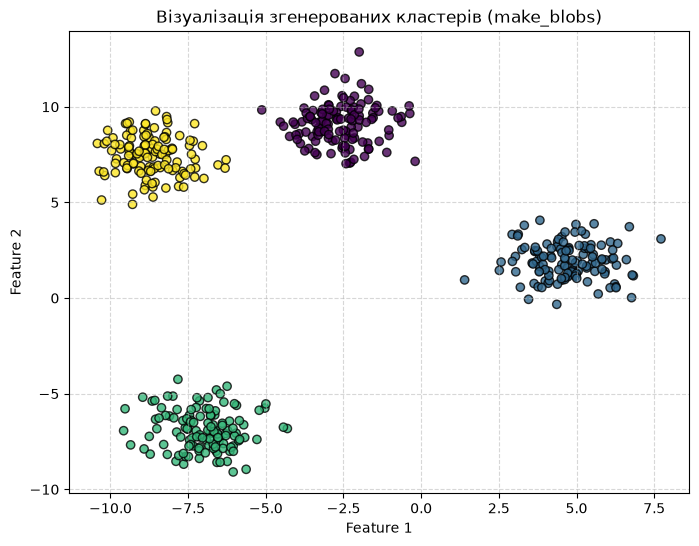

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)

df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
df['Cluster'] = y

print(df.head())

plt.figure(figsize=(8, 6))
plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)

plt.title('Візуалізація згенерованих кластерів (make_blobs)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 2

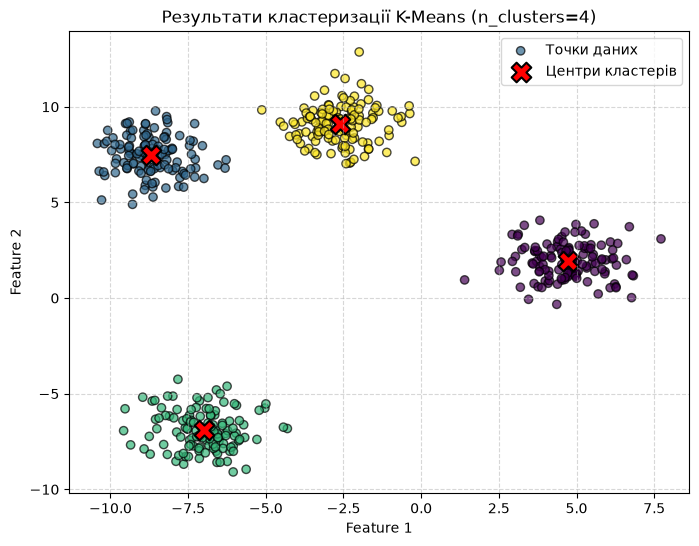

In [2]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42)

df['cluster_kmeans'] = kmeans.fit_predict(df[['Feature_1', 'Feature_2']])

centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['cluster_kmeans'],
    cmap='viridis',
    alpha=0.7,
    edgecolors='k',
    label='Точки даних',
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    marker='X',
    edgecolors='black',
    linewidths=1.5,
    label='Центри кластерів',
)

plt.title('Результати кластеризації K-Means (n_clusters=4)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 3

Унікальні мітки DBSCAN: [ 0  2  3  1 -1]


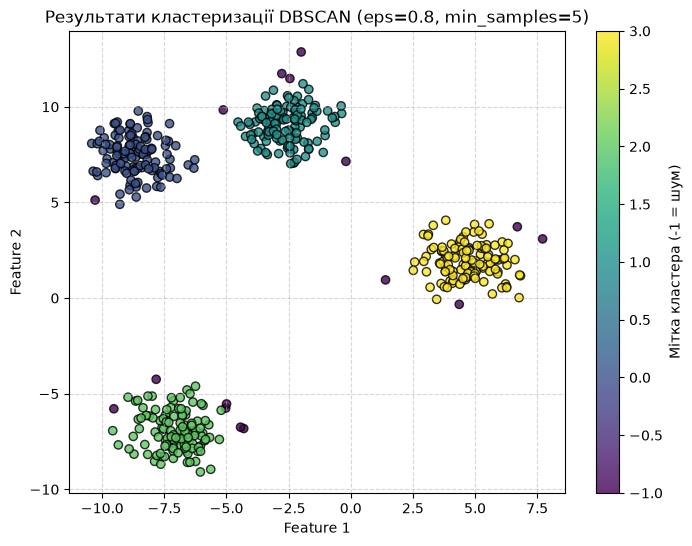

In [3]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=5)

df['cluster_dbscan'] = dbscan.fit_predict(df[['Feature_1', 'Feature_2']])

print('Унікальні мітки DBSCAN:', df['cluster_dbscan'].unique())

plt.figure(figsize=(8, 6))

plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['cluster_dbscan'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)

plt.title('Результати кластеризації DBSCAN (eps=0.8, min_samples=5)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Мітка кластера (-1 = шум)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 4

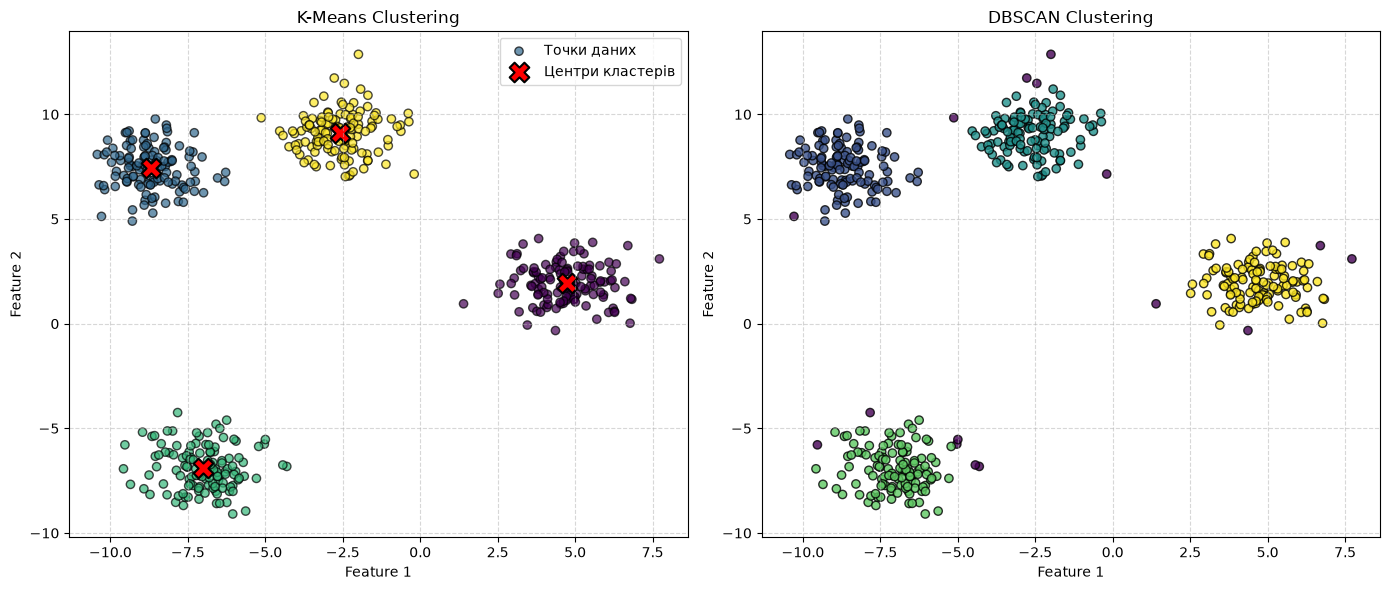

In [4]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['cluster_kmeans'],
    cmap='viridis',
    alpha=0.7,
    edgecolors='k',
    label='Точки даних',
)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    marker='X',
    edgecolors='black',
    linewidths=1.5,
    label='Центри кластерів',
)
plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.scatter(
    df['Feature_1'],
    df['Feature_2'],
    c=df['cluster_dbscan'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('clustering_comparison.png', dpi=300)

plt.show()

## Домашня

## завдання 1

     income  spending_score
0  8.786125       -1.461927
1 -3.260832        1.465231
2  1.336883       -0.441413
3 -4.363913        2.942283
4  9.339461       -1.972397


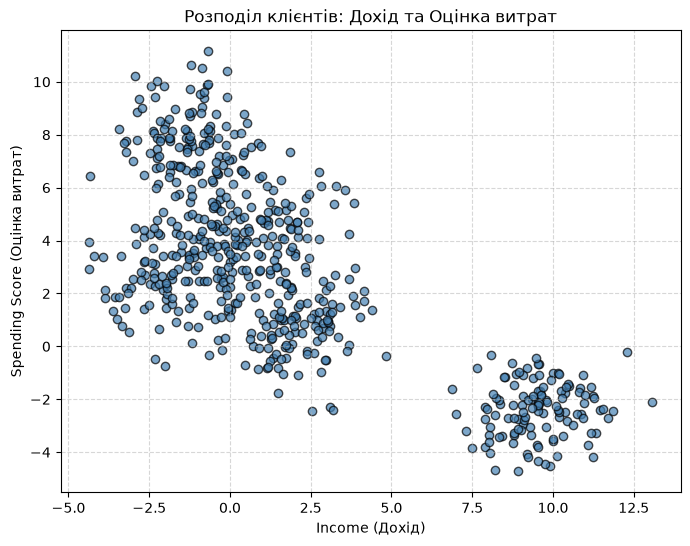

In [5]:
X, y = make_blobs(n_samples=600, centers=5, cluster_std=1.2, random_state=0)

df = pd.DataFrame(X, columns=['income', 'spending_score'])

print(df.head())

plt.figure(figsize=(8, 6))
plt.scatter(
    df['income'], df['spending_score'], c='steelblue', alpha=0.7, edgecolors='k'
)

plt.title('Розподіл клієнтів: Дохід та Оцінка витрат')
plt.xlabel('Income (Дохід)')
plt.ylabel('Spending Score (Оцінка витрат)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 2

     income  spending_score  segment
0  8.786125       -1.461927        2
1 -3.260832        1.465231        3
2  1.336883       -0.441413        0
3 -4.363913        2.942283        3
4  9.339461       -1.972397        2


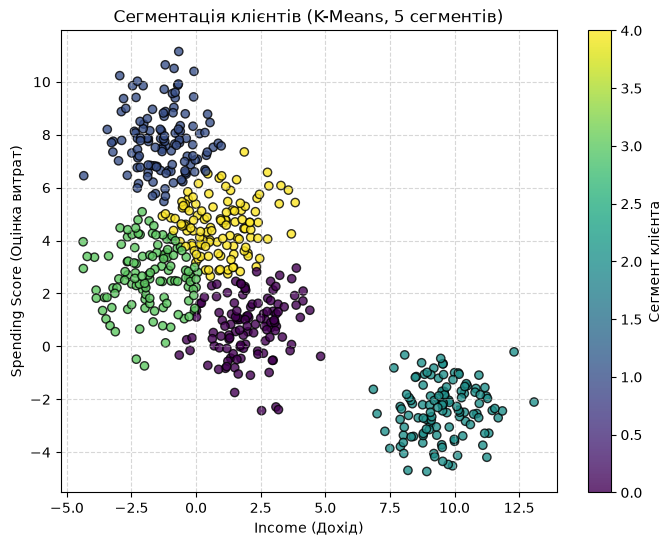

In [6]:
kmeans = KMeans(n_clusters=5, random_state=0)

df['segment'] = kmeans.fit_predict(df[['income', 'spending_score']])

print(df.head())

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['income'],
    df['spending_score'],
    c=df['segment'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)

plt.title('Сегментація клієнтів (K-Means, 5 сегментів)')
plt.xlabel('Income (Дохід)')
plt.ylabel('Spending Score (Оцінка витрат)')
plt.colorbar(scatter, label='Сегмент клієнта')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 3

Унікальні мітки DBSCAN: [ 0  1 -1]


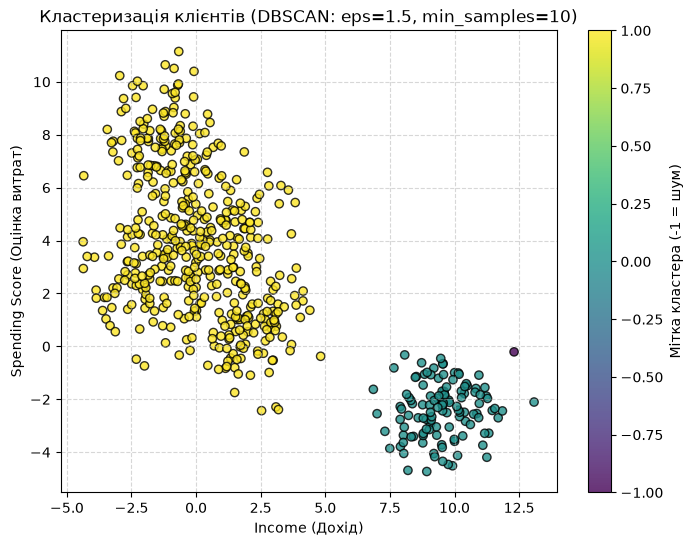

In [7]:
dbscan = DBSCAN(eps=1.5, min_samples=10)

df['cluster_dbscan'] = dbscan.fit_predict(df[['income', 'spending_score']])

print('Унікальні мітки DBSCAN:', df['cluster_dbscan'].unique())

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['income'],
    df['spending_score'],
    c=df['cluster_dbscan'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)

plt.title('Кластеризація клієнтів (DBSCAN: eps=1.5, min_samples=10)')
plt.xlabel('Income (Дохід)')
plt.ylabel('Spending Score (Оцінка витрат)')
plt.colorbar(scatter, label='Мітка кластера (-1 = шум)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## завдання 4

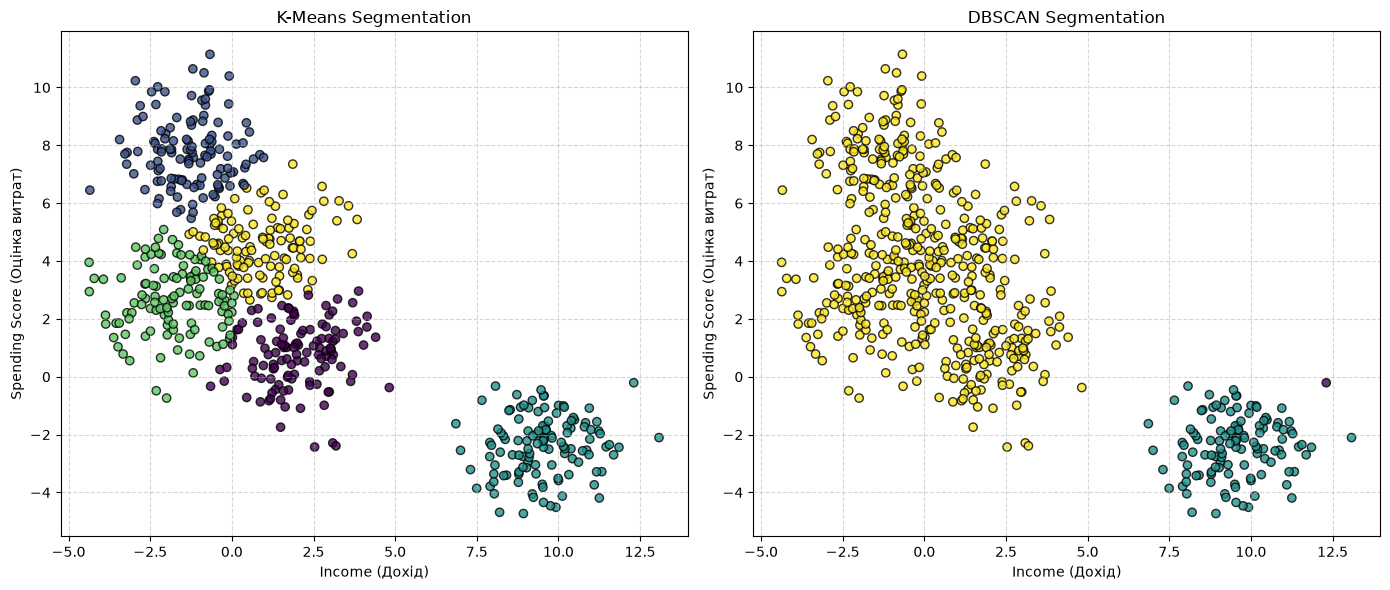

In [8]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(
    df['income'],
    df['spending_score'],
    c=df['segment'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)
plt.title('K-Means Segmentation')
plt.xlabel('Income (Дохід)')
plt.ylabel('Spending Score (Оцінка витрат)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.scatter(
    df['income'],
    df['spending_score'],
    c=df['cluster_dbscan'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
)
plt.title('DBSCAN Segmentation')
plt.xlabel('Income (Дохід)')
plt.ylabel('Spending Score (Оцінка витрат)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('client_segmentation_comparison.png', dpi=300)

plt.show()